**Assignment 1(A)**


**Importing necessary libraries**






In [ ]:
import os
import gzip
import matplotlib.pyplot as plt
import numpy as np
import tqdm

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)

from sklearn.model_selection import train_test_split

**1) Downloading the dataset**

In [ ]:
!mkdir -p fashion

!wget -q -O fashion/train-images-idx3-ubyte.gz \
https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-images-idx3-ubyte.gz

!wget -q -O fashion/train-labels-idx1-ubyte.gz \
https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/train-labels-idx1-ubyte.gz

!wget -q -O fashion/t10k-images-idx3-ubyte.gz \
https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-images-idx3-ubyte.gz

!wget -q -O fashion/t10k-labels-idx1-ubyte.gz \
https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/t10k-labels-idx1-ubyte.gz

**Loading the dataset using the sample github code**

In [ ]:
def load_mnist(path, kind='train'):
    import os
    import gzip
    import numpy as np

    """Load MNIST data from `path`"""

    labels_path = os.path.join(
        path,
        '%s-labels-idx1-ubyte.gz' % kind
    )

    images_path = os.path.join(
        path,
        '%s-images-idx3-ubyte.gz' % kind
    )

    with gzip.open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(
            lbpath.read(),
            dtype=np.uint8,
            offset=8
        )

    with gzip.open(images_path, 'rb') as imgpath:
        images = np.frombuffer(
            imgpath.read(),
            dtype=np.uint8,
            offset=16
        ).reshape(len(labels), 784)

    return images, labels

X_train_full, y_train_full = load_mnist('fashion',kind='train')
X_test, y_test = load_mnist('fashion',kind='t10k')



**2) Reading training/test images and labels into NumPy arrays**

In [ ]:
print("Training images:", X_train_full.shape)
print("Training labels:", y_train_full.shape)

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 784)
Training labels: (60000,)
Test images: (10000, 784)
Test labels: (10000,)


**3) Preprocessing the train and test images**

In [ ]:
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
print("Minimum pixel value:", X_train_full.min())
print("Maximum pixel value:", X_train_full.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


**4) Spliting training data into 80% training and 20% validation**

In [ ]:
X_train, X_val, y_train_labels, y_val_labels = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y_train_full
)

print("Training set:",X_train.shape)
print("Validation set:",X_val.shape)
print("Test set:",X_test.shape)



Training set: (48000, 784)
Validation set: (12000, 784)
Test set: (10000, 784)


**Converting labels to one-hot encoding because the classifier uses softmax and cross entropy**

In [ ]:
num_classes = 10

y_train = np.eye(num_classes)[y_train_labels]

y_val = np.eye(num_classes)[y_val_labels]

y_test_onehot = np.eye(num_classes)[y_test]

print("y_train:", y_train.shape)

print("y_val:",y_val.shape)

print("y_test:",y_test_onehot.shape)

y_train: (48000, 10)
y_val: (12000, 10)
y_test: (10000, 10)


**4.a) Training the linear classifier with softmax and cross entropy**

In [ ]:
def random_init(num_features: int,num_classes: int,seed: int = 42) -> tuple:
    np.random.seed(seed)

    W = (np.random.randn(num_features,num_classes) * 1e-5)

    b = (np.random.randn(num_classes) * 1e-3)

    return W, b

Softmax

In [ ]:
def softmax(logits: np.array) -> np.array:

    max_logits = np.max(logits,axis=-1,keepdims=True)

    exp_logits = np.exp(logits - max_logits)

    sum_exp_logits = np.sum(exp_logits,axis=-1,keepdims=True)

    softmax_output = (exp_logits / sum_exp_logits)

    return softmax_output

Forward propagation

In [ ]:
def forward(X: np.array,W: np.array,b: np.array) -> np.array:

    logits = np.dot(X,W) + b

    return softmax(logits)

Cross-entropy loss

In [ ]:
def cross_entropy_loss(y: np.array,y_pred: np.array) -> float:

    epsilon = 1e-15

    y_pred = np.clip(y_pred,epsilon,1 - epsilon)

    return (-np.sum(y * np.log(y_pred)) / y.shape[0])

Backward propagation

In [ ]:
def backward(X: np.array,y: np.array,y_pred: np.array) -> tuple:

    m = X.shape[0]

    dW = ( 1 / m) * np.dot(X.T,y_pred - y)
    db = (1 / m) * np.sum(y_pred - y,axis=0)

    return dW, db

Update weights

In [ ]:
def update(W: np.array,b: np.array,dW: np.array,db: np.array,lr: float) ->tuple:

    W = W - lr * dW
    b = b - lr * db

    return W, b

**Validation Fuction**

In [ ]:
def validate(X: np.array,y: np.array,W: np.array,b: np.array,batch_size: int)-> tuple:

    total_loss = 0.0
    total_samples = 0
    predictions = []

    for i in range(0,X.shape[0], batch_size):

        X_batch = X[i:i + batch_size]
        y_batch = y[i:i + batch_size]
        y_pred = forward(X_batch,W,b)
        batch_loss = cross_entropy_loss(y_batch,y_pred)
        batch_samples = X_batch.shape[0]
        total_loss += (batch_loss * batch_samples)
        total_samples += batch_samples
        predictions.append(y_pred)

    average_loss = (total_loss /total_samples)
    y_pred = np.concatenate(predictions,axis=0)
    return average_loss, y_pred

**Training Function**

In [ ]:
def train(
    X_train: np.array,
    y_train: np.array,
    X_val: np.array,
    y_val: np.array,
    num_classes: int,
    num_epoch: int,
    lr: float,
    batch_size: int,
    seed: int = 42
) -> tuple:

    num_samples, num_features = X_train.shape

    W, b = random_init(
        num_features,
        num_classes,
        seed
    )

    loss = {
        "train": [],
        "val": []
    }

    for epoch in range(num_epoch):

        # Shuffle training data
        permutation = np.random.permutation(
            num_samples
        )

        X_shuffled = X_train[
            permutation
        ]

        y_shuffled = y_train[
            permutation
        ]

        epoch_loss = 0.0

        loop = tqdm.tqdm(
            range(
                0,
                num_samples,
                batch_size
            ),
            leave=False,
            ncols=100
        )

        for i in loop:

            X_batch = X_shuffled[
                i:i + batch_size
            ]

            y_batch = y_shuffled[
                i:i + batch_size
            ]

            # Forward pass
            y_pred = forward(
                X_batch,
                W,
                b
            )

            # Calculate loss
            loss_batch = cross_entropy_loss(
                y_batch,
                y_pred
            )

            epoch_loss += (
                loss_batch *
                X_batch.shape[0]
            )

            # Backward pass
            dW, db = backward(
                X_batch,
                y_batch,
                y_pred
            )

            # Update weights
            W, b = update(
                W,
                b,
                dW,
                db,
                lr
            )

            loop.set_description(
                f"Epoch [{epoch + 1}/{num_epoch}]"
            )

            loop.set_postfix(
                loss=loss_batch
            )

        # Average training loss
        train_loss = (
            epoch_loss /
            num_samples
        )

        # Validation loss
        val_loss, _ = validate(
            X_val,
            y_val,
            W,
            b,
            batch_size
        )

        loss["train"].append(
            train_loss
        )

        loss["val"].append(
            val_loss
        )

        print(
            f"Epoch [{epoch + 1:3d}/{num_epoch}] "
            f"Train Loss: {train_loss:.4f} "
            f"Val Loss: {val_loss:.4f}"
        )

    return W, b, loss

**Plot Learning Curve**

In [ ]:
def plot_learning_curve(
    loss,
    batch_size,
    lr
):

    epochs = range(
        1,
        len(loss["train"]) + 1
    )

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        epochs,
        loss["train"],
        color="blue",
        label="Training Loss"
    )

    plt.plot(
        epochs,
        loss["val"],
        color="red",
        label="Validation Loss"
    )

    plt.xlabel("Epoch")

    plt.ylabel(
        "Cross-Entropy Loss"
    )

    plt.title(
        f"Batch Size = {batch_size}, "
        f"Learning Rate = {lr}"
    )

    plt.legend()

    plt.grid()

    plt.show()

**Six Experiments**

In [ ]:
batch_sizes = [2048,1024,512]
learning_rates = [0.001,0.0001]
epochs = 100

**Running Six Experiments**

In [ ]:
results = {}

for lr in learning_rates:

    for batch_size in batch_sizes:

        print("\n")
        print("=" * 70)

        print(
            f"Batch Size = {batch_size}"
        )

        print(
            f"Learning Rate = {lr}"
        )

        print("=" * 70)

        W, b, loss = train(
            X_train,
            y_train,
            X_val,
            y_val,
            num_classes=10,
            num_epoch=100,
            lr=lr,
            batch_size=batch_size,
            seed=42
        )

        results[
            (batch_size, lr)
        ] = {
            "W": W,
            "b": b,
            "loss": loss
        }



Batch Size = 2048
Learning Rate = 0.001


Epoch [  1/100] Train Loss: 2.2737 Val Loss: 2.2425


Epoch [  2/100] Train Loss: 2.2171 Val Loss: 2.1897


Epoch [  3/100] Train Loss: 2.1666 Val Loss: 2.1418


Epoch [  4/100] Train Loss: 2.1204 Val Loss: 2.0976


...

Epoch [ 96/100] Train Loss: 1.3609 Val Loss: 1.3603


Epoch [ 97/100] Train Loss: 1.3566 Val Loss: 1.3560


Epoch [ 98/100] Train Loss: 1.3523 Val Loss: 1.3517


Epoch [ 99/100] Train Loss: 1.3481 Val Loss: 1.3475


Epoch [100/100] Train Loss: 1.3440 Val Loss: 1.3434


**Plotting all Six Experiments**

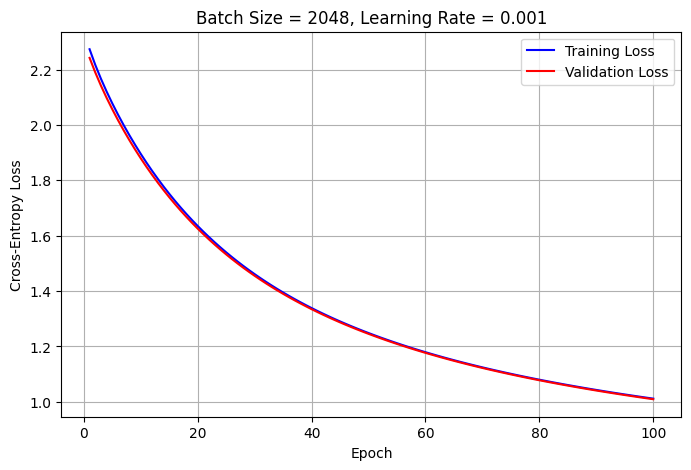

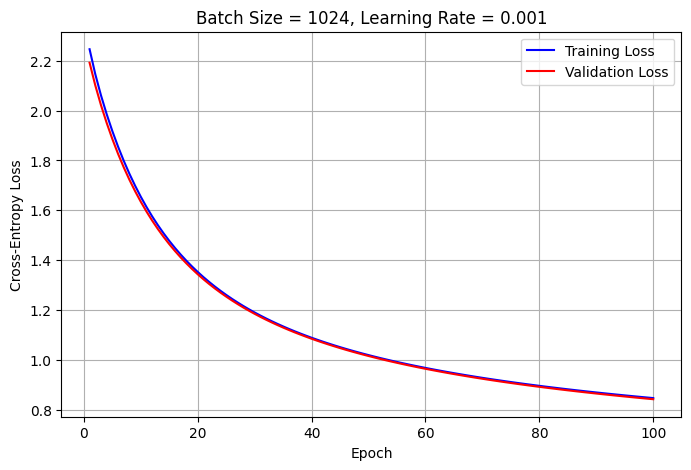

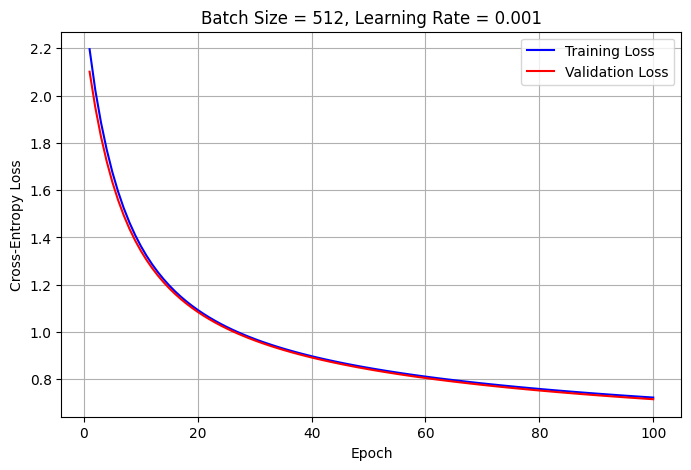

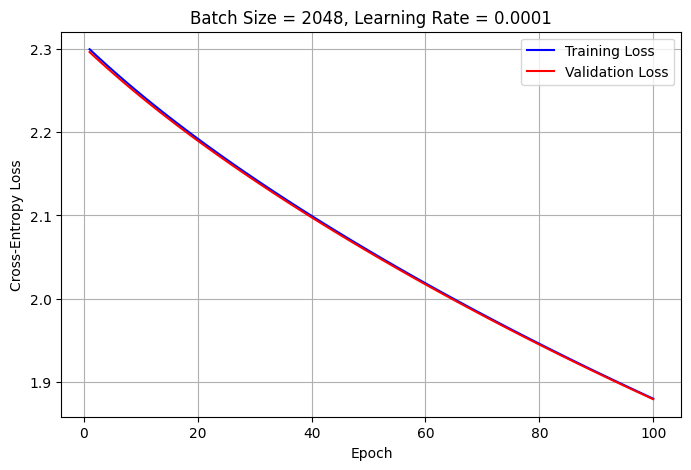

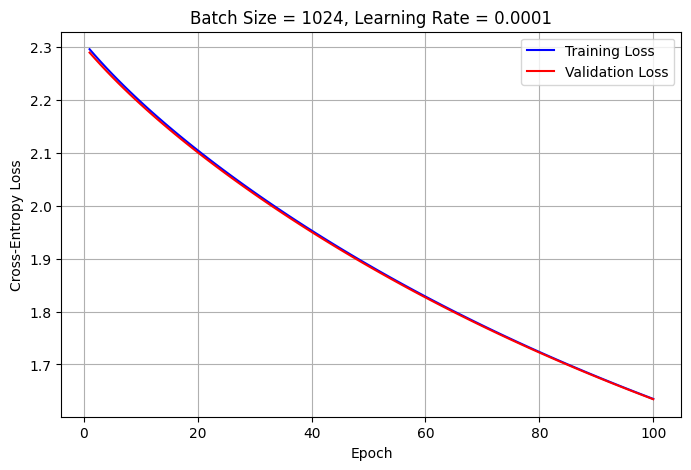

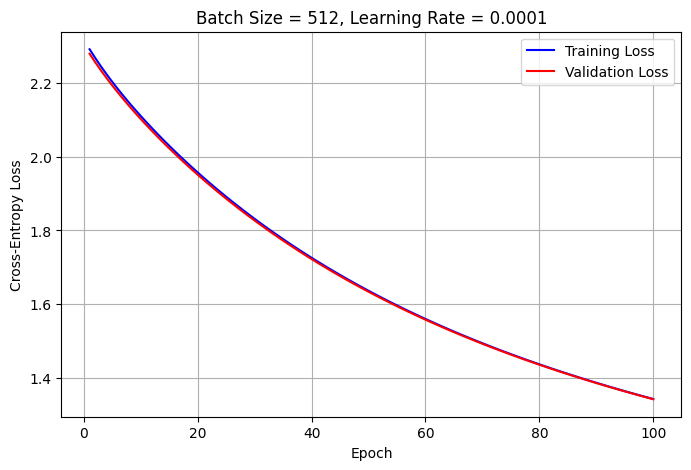

In [ ]:
for (batch_size,lr), result in results.items():

    plot_learning_curve(result["loss"],batch_size,lr)

**5)**

**Validation macro F1 for every experiment**

In [ ]:
experiment_results = []

for (
    batch_size,
    lr
), result in results.items():

    W = result["W"]

    b = result["b"]

    val_loss, val_pred = validate(
        X_val,
        y_val,
        W,
        b,
        batch_size
    )

    val_pred_labels = np.argmax(
        val_pred,
        axis=1
    )

    macro_f1 = f1_score(
        y_val_labels,
        val_pred_labels,
        average="macro"
    )

    accuracy = accuracy_score(
        y_val_labels,
        val_pred_labels
    )

    result["macro_f1"] = macro_f1

    result["val_accuracy"] = accuracy

    result["val_loss"] = val_loss

    experiment_results.append({
        "Batch Size": batch_size,
        "Learning Rate": lr,
        "Validation Loss": val_loss,
        "Validation Accuracy": accuracy,
        "Validation Macro F1": macro_f1
    })

    print(
        f"Batch Size = {batch_size:4d} | "
        f"Learning Rate = {lr:<7} | "
        f"Val Loss = {val_loss:.4f} | "
        f"Val Accuracy = {accuracy:.4f} | "
        f"Macro F1 = {macro_f1:.4f}"
    )

Batch Size = 2048 | Learning Rate = 0.001   | Val Loss = 1.0094 | Val Accuracy = 0.6910 | Macro F1 = 0.6526
Batch Size = 1024 | Learning Rate = 0.001   | Val Loss = 0.8422 | Val Accuracy = 0.7390 | Macro F1 = 0.7259
Batch Size =  512 | Learning Rate = 0.001   | Val Loss = 0.7153 | Val Accuracy = 0.7812 | Macro F1 = 0.7763
Batch Size = 2048 | Learning Rate = 0.0001  | Val Loss = 1.8793 | Val Accuracy = 0.6547 | Macro F1 = 0.5921
Batch Size = 1024 | Learning Rate = 0.0001  | Val Loss = 1.6341 | Val Accuracy = 0.6618 | Macro F1 = 0.5952
Batch Size =  512 | Learning Rate = 0.0001  | Val Loss = 1.3434 | Val Accuracy = 0.6647 | Macro F1 = 0.5992


**Experiment Comparison**

In [ ]:
import pandas as pd
results_df = pd.DataFrame(experiment_results)
results_df

,Batch Size,Learning Rate,Validation Loss,Validation Accuracy,Validation Macro F1
0,2048,0.0010,1.009357,0.691000,0.652610
1,1024,0.0010,0.842152,0.739000,0.725855
2,512,0.0010,0.715283,0.781167,0.776303
3,2048,0.0001,1.879300,0.654667,0.592125
4,1024,0.0001,1.634130,0.661833,0.595249
5,512,0.0001,1.343386,0.664750,0.599165


**Best hyperparameters**

In [ ]:
best_index = results_df["Validation Macro F1"].idxmax()

best_batch_size = int(
    results_df.loc[
        best_index,
        "Batch Size"
    ]
)

best_lr = float(
    results_df.loc[
        best_index,
        "Learning Rate"
    ]
)

best_macro_f1 = results_df.loc[
    best_index,
    "Validation Macro F1"
]

print(
    "Best Batch Size:",
    best_batch_size
)

print(
    "Best Learning Rate:",best_lr)

print(
    "Best Validation Macro F1:",
    best_macro_f1
)

Best Batch Size: 512
Best Learning Rate: 0.001
Best Validation Macro F1: 0.7763029946401949


**Final Training**

In [ ]:
final_W, final_b, final_loss = train(
    X_train,
    y_train,
    X_val,
    y_val,
    num_classes=10,
    num_epoch=100,
    lr=best_lr,
    batch_size=best_batch_size,
    seed=42
)

Epoch [  1/100] Train Loss: 2.1962 Val Loss: 2.1012


Epoch [  2/100] Train Loss: 2.0236 Val Loss: 1.9505


Epoch [  3/100] Train Loss: 1.8866 Val Loss: 1.8265


Epoch [  4/100] Train Loss: 1.7725 Val Loss: 1.7223


Epoch [  5/100] Train Loss: 1.6762 Val Loss: 1.6340


...

Epoch [ 96/100] Train Loss: 0.7288 Val Loss: 0.7218


Epoch [ 97/100] Train Loss: 0.7272 Val Loss: 0.7201


Epoch [ 98/100] Train Loss: 0.7256 Val Loss: 0.7185


Epoch [ 99/100] Train Loss: 0.7240 Val Loss: 0.7169


Epoch [100/100] Train Loss: 0.7224 Val Loss: 0.7153


**Plot final training**

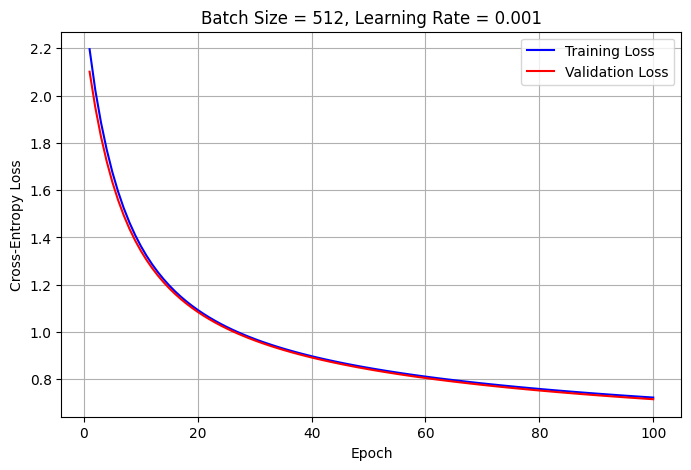

In [ ]:
plot_learning_curve(final_loss,best_batch_size,best_lr)

**Running final test set**

In [ ]:
test_loss, test_pred = validate(X_test,y_test_onehot,final_W,final_b,best_batch_size)
print("Test Loss:",test_loss)

Test Loss: 0.7377992822727653


**Converting predictions to class numbers**

In [ ]:
y_test_pred = np.argmax(test_pred,axis=1)
print("Predictions shape:",y_test_pred.shape)

Predictions shape: (10000,)


**Test accuracy**

In [ ]:
test_accuracy = accuracy_score(y_test,y_test_pred)
print( f"Test Accuracy: {test_accuracy:.4f}")

Test Accuracy: 0.7608


**Test macro F1**

In [ ]:
test_macro_f1 = f1_score(y_test,y_test_pred,average="macro")
print(f"Test Macro F1: {test_macro_f1:.4f}")

Test Macro F1: 0.7539


In [ ]:
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

**Performance**

In [ ]:
print(classification_report(y_test,y_test_pred,target_names=classes,digits=4))

              precision    recall  f1-score   support

 T-shirt/top     0.7320    0.7840    0.7571      1000
     Trouser     0.9712    0.9100    0.9396      1000
    Pullover     0.6674    0.6300    0.6481      1000
       Dress     0.7476    0.8470    0.7942      1000
        Coat     0.6064    0.7440    0.6682      1000
      Sandal     0.9577    0.6120    0.7468      1000
       Shirt     0.5270    0.3410    0.4141      1000
     Sneaker     0.7429    0.8840    0.8073      1000
         Bag     0.8856    0.9210    0.9029      1000
  Ankle boot     0.7978    0.9350    0.8610      1000

    accuracy                         0.7608     10000
   macro avg     0.7636    0.7608    0.7539     10000
weighted avg     0.7636    0.7608    0.7539     10000



**Confusion matrix**

In [ ]:
cm = confusion_matrix(y_test,y_test_pred)
print(cm)

[[784   7  12  93   9   0  67   0  27   1]
 [ 12 910  16  46  12   0   2   0   2   0]
 [ 17   0 630  11 231   0  89   0  21   1]
 [ 39  12   4 847  33   1  59   0   5   0]
 [  0   4 126  51 744   0  67   0   8   0]
 [  1   0   0   3   0 612   0 234  14 136]
 [217   3 143  60 196   0 341   0  40   0]
 [  0   0   0   0   0  19   0 884   0  97]
 [  1   1  13  20   2   2  22  16 921   2]
 [  0   0   0   2   0   5   0  56   2 935]]


<Figure size 1000x1000 with 0 Axes>

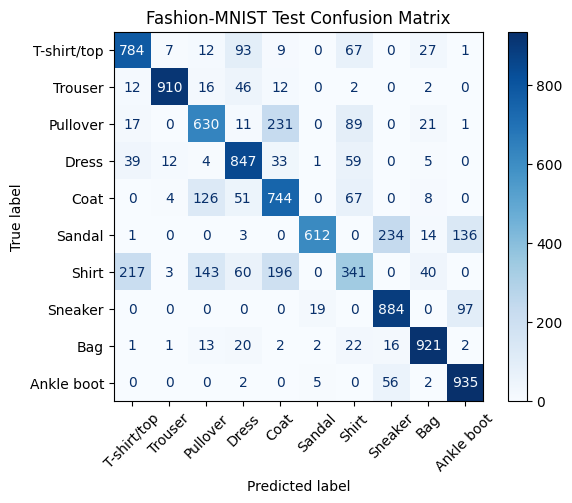

In [ ]:
plt.figure(figsize=(10, 10))

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=classes)

disp.plot(xticks_rotation=45,cmap="Blues")

plt.title("Fashion-MNIST Test Confusion Matrix")

plt.show()

**Learned weight for each class**

In [ ]:
print("Weight shape:",final_W.shape)
print("Bias shape:",final_b.shape)

Weight shape: (784, 10)
Bias shape: (10,)


**6)**

**Plot Weight Images**

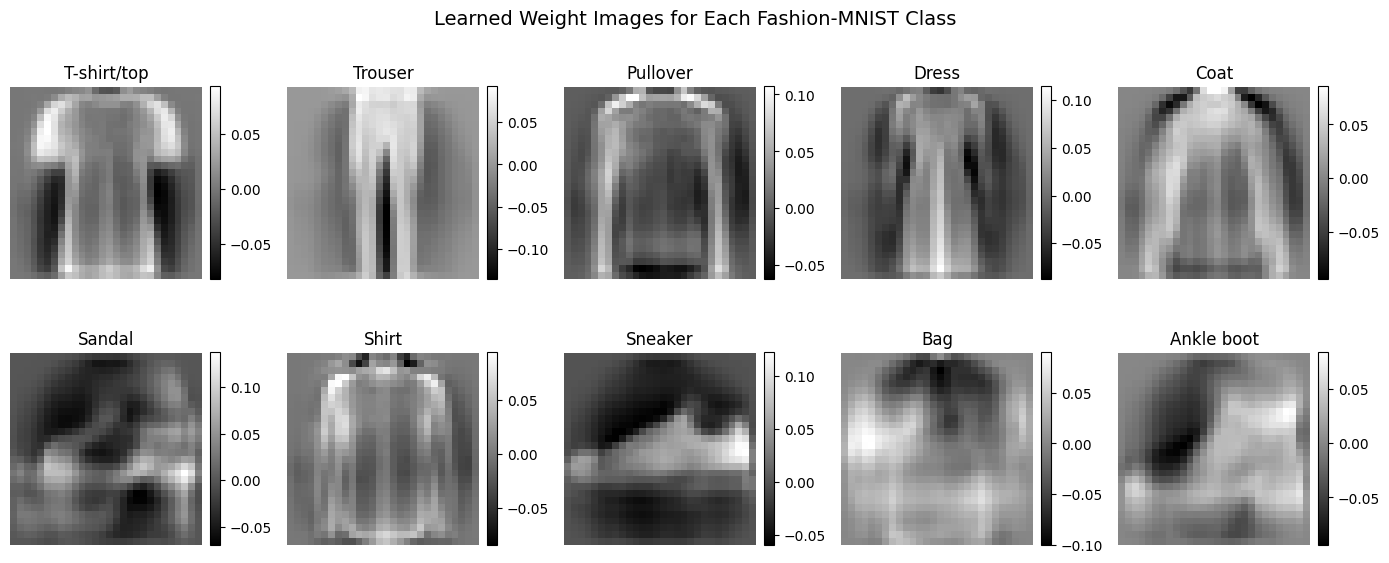

In [ ]:
fig, axes = plt.subplots(2,5, figsize=(14, 6))

for i in range(10):

    weight_image = final_W[
        :,
        i
    ].reshape(28, 28)

    ax = axes[
        i // 5,
        i % 5
    ]

    im = ax.imshow(
        weight_image,
        cmap="gray"
    )

    ax.set_title(
        classes[i]
    )

    ax.axis("off")

    plt.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

plt.suptitle("Learned Weight Images for Each Fashion-MNIST Class",fontsize=14)
plt.tight_layout()
plt.show()